# 01 — Análise exploratória (EDA) do TrashNet

Objetivo: conhecer o `dataset-resized.zip` antes de treinar — quantidade, dimensões, canais,
integridade, exemplos de cada classe, efeito das resoluções usadas e a divisão
treino/validação/teste. As figuras são salvas em `results/figures/` para o artigo.

Pré-requisito: o zip descompactado em `data/` (ver README).

In [1]:
import hashlib
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.config import CLASSES, DATA_DIR, EXPERIMENTOS, SEED
from src.data import ler_imagem, pesos_de_classe
from src.dataset import encontrar_raiz, listar_imagens
from src.split import carregar_split, tabela_contagens, verificar_split
from src.viz import AZUL, COR_CONJUNTO, ROTULO_CONJUNTO, TEXTO_2, aplicar_estilo, salvar

aplicar_estilo()
pd.set_option("display.precision", 3)
DADOS = encontrar_raiz(DATA_DIR)
print("Pasta das imagens:", DADOS.relative_to(RAIZ))

Pasta das imagens: data\dataset-resized


## 1. Quantidade de imagens por classe

In [2]:
df = listar_imagens(DATA_DIR)
contagem = df["classe"].value_counts().reindex(CLASSES)
resumo = pd.DataFrame({"imagens": contagem, "proporcao_%": 100 * contagem / len(df)})
print(f"Total: {len(df)} imagens em {df['classe'].nunique()} classes")
print(f"Razão maior/menor classe: {contagem.max() / contagem.min():.2f} ({contagem.idxmax()} / {contagem.idxmin()})")
resumo

Total: 2527 imagens em 6 classes
Razão maior/menor classe: 4.34 (paper / trash)


,imagens,proporcao_%
classe,,
glass,501,19.826
paper,594,23.506
cardboard,403,15.948
plastic,482,19.074
metal,410,16.225
trash,137,5.421


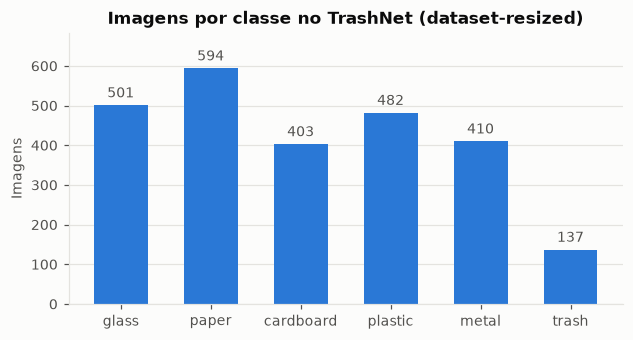

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
barras = ax.bar(CLASSES, contagem.values, color=AZUL, width=0.6)
ax.bar_label(barras, padding=3, color=TEXTO_2)
ax.set_ylabel("Imagens")
ax.set_title("Imagens por classe no TrashNet (dataset-resized)")
ax.set_ylim(0, contagem.max() * 1.15)
salvar(fig, "eda_01_classes.png")
plt.show()

## 2. Dimensões, canais e integridade

In [4]:
print("Dimensões (largura x altura) e modo de cor:")
df.groupby(["largura", "altura", "modo"]).size().rename("imagens").to_frame()

Dimensões (largura x altura) e modo de cor:


,,,imagens
largura,altura,modo,
512,384,RGB,2527


In [5]:
# Integridade: decodifica cada imagem por completo (detecta arquivo truncado/corrompido),
# confere 3 canais e calcula hash do arquivo (duplicata exata).




linhas = []
for caminho in df["caminho"]:
    arquivo = DADOS / caminho
    erro = None
    try:
        with Image.open(arquivo) as img:
            img.load()
            arr = np.asarray(img.convert("RGB"))

    except Exception as e:  # noqa: BLE001
        erro, arr = repr(e), None
    linhas.append({
        "caminho": caminho,
        "erro": erro,
        "canais": None if arr is None else arr.shape[2],
        "md5": hashlib.md5(arquivo.read_bytes()).hexdigest(),

        "brilho_medio": None if arr is None else arr.mean(),
        "desvio_pixels": None if arr is None else arr.std(),
    })
integ = df.merge(pd.DataFrame(linhas), on="caminho")
print("Imagens com erro de leitura:", integ["erro"].notna().sum())
print("Canais:", integ["canais"].value_counts().to_dict())
print("Arquivos duplicados (md5 idêntico):", integ["md5"].duplicated(keep=False).sum())

Imagens com erro de leitura: 0
Canais: {3: 2527}
Arquivos duplicados (md5 idêntico): 6


In [6]:
# Duplicatas exatas: arquivos byte a byte idênticos, com a classe e o conjunto de cada cópia.
split = carregar_split()
integ = integ.merge(split[["caminho", "conjunto"]], on="caminho")
dup = integ[integ["md5"].duplicated(keep=False)].sort_values(["md5", "caminho"])
pares = [g for _, g in dup.groupby("md5", sort=False)]
print(f"Pares de arquivos idênticos: {len(pares)}")
print("Pares com rótulos diferentes:", sum(g["classe"].nunique() > 1 for g in pares))
print("Pares que cruzam conjuntos:", sum(g["conjunto"].nunique() > 1 for g in pares))
print("Pares que envolvem o teste:", sum((g["conjunto"] == "teste").any() for g in pares))
dup[["caminho", "classe", "conjunto", "md5"]]

Pares de arquivos idênticos: 3
Pares com rótulos diferentes: 3
Pares que cruzam conjuntos: 2
Pares que envolvem o teste: 0


,caminho,classe,conjunto,md5
18,glass/glass115.jpg,glass,treino,70df08c3ce6d55e25df4edbbe45e5fe3
2381,metal/metal91.jpg,metal,validacao,70df08c3ce6d55e25df4edbbe45e5fe3
85,glass/glass176.jpg,glass,validacao,a2236bc6f8eae80bf7d6c5f259df8760
1557,plastic/plastic152.jpg,plastic,treino,a2236bc6f8eae80bf7d6c5f259df8760
321,glass/glass389.jpg,glass,treino,e52ec9a8f6089b5780728b148c9f795e
1757,plastic/plastic332.jpg,plastic,treino,e52ec9a8f6089b5780728b148c9f795e


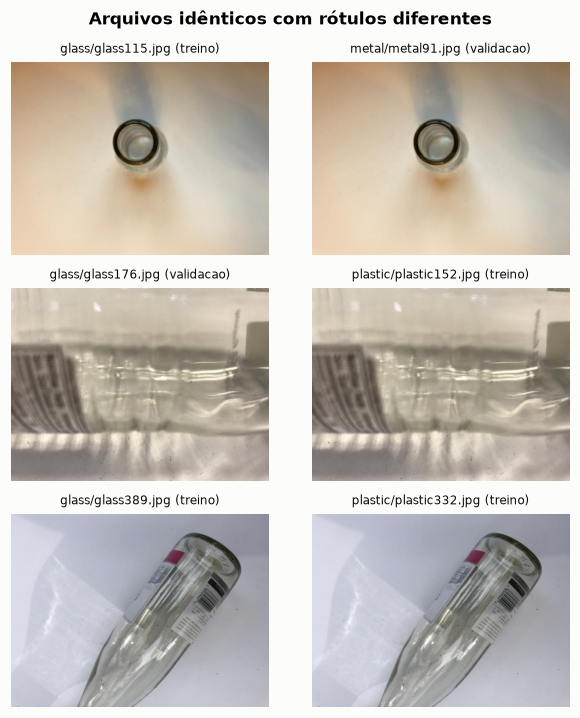

In [7]:
if pares:
    fig, axs = plt.subplots(len(pares), 2, figsize=(5.6, 2.2 * len(pares)), squeeze=False)
    for i, g in enumerate(pares):
        for j in range(2):
            r = g.iloc[j]; ax = axs[i, j]; ax.axis("off")
            ax.imshow(Image.open(DADOS / r["caminho"]))
            ax.set_title(f"{r['caminho']} ({r['conjunto']})", fontsize=8, fontweight="normal")
    fig.suptitle("Arquivos idênticos com rótulos diferentes", fontweight="bold")
    plt.tight_layout()
    salvar(fig, "eda_06_duplicatas.png")
    plt.show()

## 3. Exemplos de cada classe

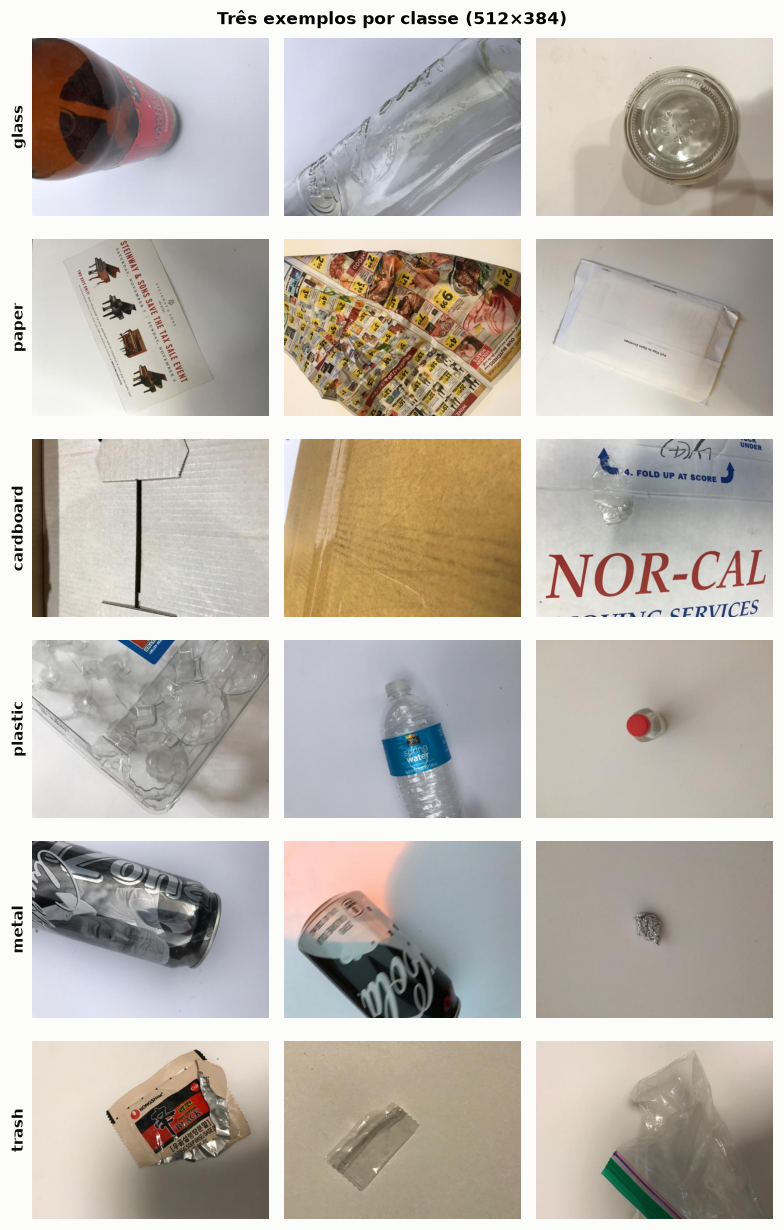

In [8]:
rng = np.random.default_rng(SEED)
n_ex = 3
fig, axs = plt.subplots(len(CLASSES), n_ex, figsize=(2.4 * n_ex, 1.9 * len(CLASSES)))
for i, classe in enumerate(CLASSES):
    escolhidas = rng.choice(df.loc[df["classe"] == classe, "caminho"].to_numpy(), n_ex, replace=False)
    for j, caminho in enumerate(escolhidas):
        ax = axs[i, j]
        ax.imshow(Image.open(DADOS / caminho)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values(): s.set_visible(False)
        if j == 0:
            ax.set_ylabel(classe, fontsize=10, color="#0b0b0b", fontweight="bold")
fig.suptitle("Três exemplos por classe (512×384)", fontweight="bold")
plt.tight_layout()
salvar(fig, "eda_02_exemplos_por_classe.png")
plt.show()

## 4. Mesma imagem nas três resoluções dos experimentos

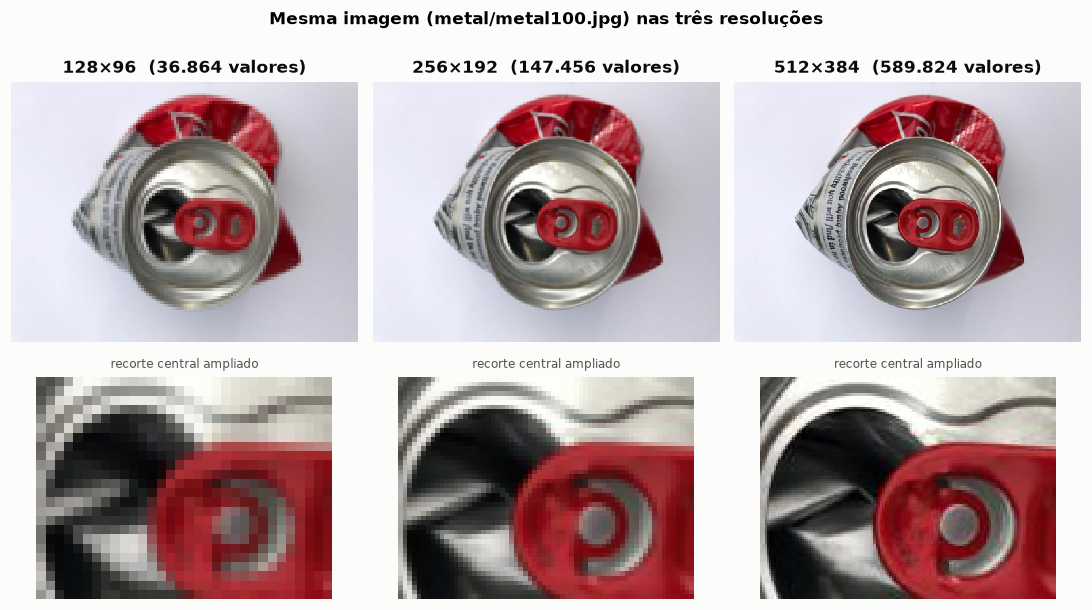

In [9]:
exemplo = "metal/metal100.jpg" if (DADOS / "metal/metal100.jpg").exists() else df.iloc[0]["caminho"]
resolucoes = [(128, 96), (256, 192), (512, 384)]
fig, axs = plt.subplots(2, 3, figsize=(10, 5.6), gridspec_kw={"height_ratios": [3, 2]})
for j, res in enumerate(resolucoes):
    arr = ler_imagem(DADOS / exemplo, res)
    ax = axs[0, j]
    ax.imshow(arr, interpolation="nearest"); ax.axis("off")
    ax.set_title(f"{res[0]}×{res[1]}  ({res[0] * res[1] * 3:,} valores)".replace(",", "."))
    # recorte central de 1/4 da largura para mostrar a perda de detalhe
    h, w = arr.shape[:2]
    recorte = arr[h // 2 - h // 8: h // 2 + h // 8, w // 2 - w // 8: w // 2 + w // 8]
    axs[1, j].imshow(recorte, interpolation="nearest"); axs[1, j].axis("off")
    axs[1, j].set_title("recorte central ampliado", fontsize=8, fontweight="normal", color=TEXTO_2)
fig.suptitle(f"Mesma imagem ({exemplo}) nas três resoluções", fontweight="bold")
plt.tight_layout()
salvar(fig, "eda_03_resolucoes.png")
plt.show()

## 5. Brilho e contraste por classe

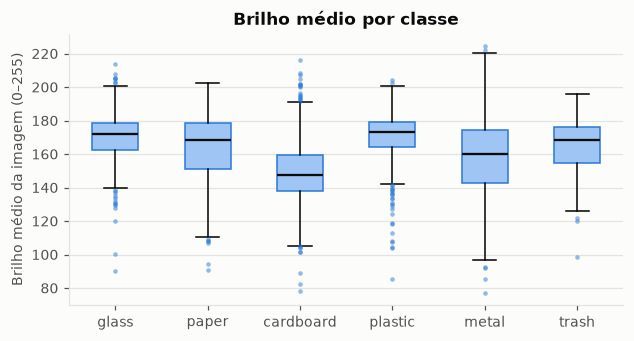

brilho_medio         desvio_pixels        
                  mean     std          mean     std
classe                                              
glass          169.997  14.825        50.089  17.181
paper          164.055  19.478        49.917  16.759
cardboard      148.956  21.918        51.916  11.511
plastic        170.052  14.837        39.953  12.441
metal          157.910  25.521        57.231  14.572
trash          164.654  17.452        46.638  12.412

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
dados = [integ.loc[integ["classe"] == c, "brilho_medio"] for c in CLASSES]
bp = ax.boxplot(dados, tick_labels=CLASSES, patch_artist=True, widths=0.5,
                medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                flierprops={"marker": "o", "markersize": 3, "markerfacecolor": AZUL, "markeredgecolor": "none", "alpha": 0.5})
for caixa in bp["boxes"]:
    caixa.set(facecolor="#9ec5f4", edgecolor=AZUL)
ax.set_ylabel("Brilho médio da imagem (0–255)")
ax.set_title("Brilho médio por classe")
salvar(fig, "eda_04_brilho_por_classe.png")
plt.show()
integ.groupby("classe")[["brilho_medio", "desvio_pixels"]].agg(["mean", "std"]).reindex(CLASSES)

## 6. Divisão treino / validação / teste

Divisão estratificada 70/15/15 com semente 42, gerada uma vez por `python -m src.split` e salva em
`results/split.csv`. Os seis experimentos leem esse mesmo arquivo.

In [11]:
tab = verificar_split(split)  # falha se houver imagem em dois conjuntos ou proporção errada
tab_total = tab.assign(total=tab.sum(axis=1))
tab_total.loc["total"] = tab_total.sum()
print("Sem vazamento: nenhuma imagem aparece em mais de um conjunto.")
tab_total

Sem vazamento: nenhuma imagem aparece em mais de um conjunto.


conjunto,treino,validacao,teste,total
classe,,,,
glass,350,75,76,501
paper,416,89,89,594
cardboard,282,61,60,403
plastic,337,72,73,482
metal,287,61,62,410
trash,96,21,20,137
total,1768,379,380,2527


In [12]:
(100 * tab / tab.sum()).round(1).rename(columns=ROTULO_CONJUNTO)  # % de cada classe dentro do conjunto

conjunto,Treino,Validação,Teste
classe,,,
glass,19.8,19.8,20.0
paper,23.5,23.5,23.4
cardboard,16.0,16.1,15.8
plastic,19.1,19.0,19.2
metal,16.2,16.1,16.3
trash,5.4,5.5,5.3


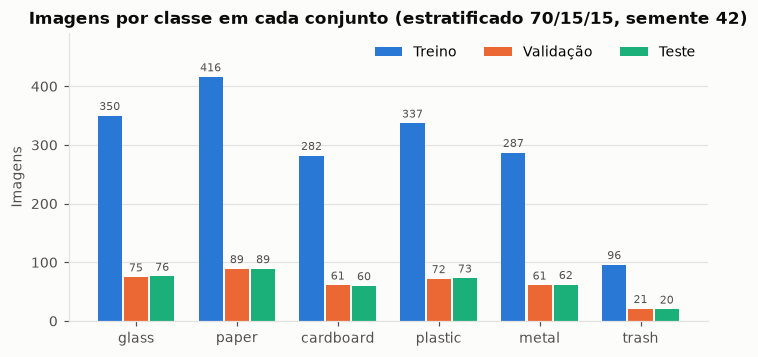

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(CLASSES)); larg = 0.26
for k, conj in enumerate(["treino", "validacao", "teste"]):
    b = ax.bar(x + (k - 1) * larg, tab[conj].values, width=larg - 0.02, color=COR_CONJUNTO[conj], label=ROTULO_CONJUNTO[conj])
    ax.bar_label(b, padding=2, fontsize=7, color=TEXTO_2)
ax.set_xticks(x, CLASSES)
ax.set_ylabel("Imagens")
ax.set_title("Imagens por classe em cada conjunto (estratificado 70/15/15, semente 42)")
ax.legend(ncols=3, loc="upper right")
ax.set_ylim(0, tab.values.max() * 1.18)
salvar(fig, "eda_05_split_por_classe.png")
plt.show()

## 7. Pesos de classe (experimentos 2 e 4)

Peso da classe *c* = n_treino / (6 · n_treino,c), calculado só com as contagens do treino.

In [14]:
pesos = pesos_de_classe(split)
pd.DataFrame({
    "imagens_treino": tab["treino"],
    "peso": [pesos[i] for i in range(len(CLASSES))],
}, index=CLASSES)

,imagens_treino,peso
glass,350,0.842
paper,416,0.708
cardboard,282,1.045
plastic,337,0.874
metal,287,1.027
trash,96,3.069


## 8. Dificuldades visuais e tratamento

**O que os dados mostram**

- **Integridade:** as 2.527 imagens abrem sem erro, todas 512×384, RGB, 3 canais. Nenhuma conversão foi necessária além de garantir RGB na leitura.
- **Desequilíbrio:** `trash` tem 137 imagens (5,4%), 4,3× menos que `paper`. Um modelo pode ignorar `trash` e ainda ter boa acurácia; por isso a métrica de seleção é o F1 macro e os experimentos 2 e 4 usam pesos de classe.
- **Ambiente controlado:** quase todas as fotos têm um único objeto sobre fundo branco/cinza claro, com iluminação parecida. O brilho médio fica entre ~149 e ~170 em todas as classes (seção 5), então o fundo não separa as classes: o modelo precisa olhar o objeto. Isso também limita o uso em fotos reais (fundo variado, vários objetos, sujeira).
- **Materiais transparentes:** garrafas de vidro e de plástico transparentes têm aparência muito parecida (reflexos, rótulos). `plastic` tem o menor contraste interno (desvio dos pixels ~40, contra ~50–57 nas demais), o que deixa menos informação de textura.
- **Papel × papelão:** os dois aparecem como superfícies planas, às vezes brancas e com texto impresso; a diferença está na espessura e na textura ondulada, que são detalhes finos.
- **Metal:** reflexos fortes e latas com rótulos coloridos, que lembram embalagens de outras classes.
- **`trash` heterogênea:** mistura sachês metalizados, sacos plásticos e embalagens diversas — visualmente parecida com `plastic` e `metal`, e com poucos exemplos.
- **Escala e orientação:** alguns objetos ocupam poucos pixels (tampinha, bolinha de alumínio) e aparecem em qualquer rotação. Em 128×96 detalhes como textura e texto quase somem (seção 4).
- **Duplicatas com rótulos diferentes:** três pares de arquivos idênticos byte a byte estão em classes diferentes (glass/metal, plastic/glass, glass/plastic). Dois pares cruzam treino e validação; nenhum envolve o teste.

**Tratamento adotado**

| Dificuldade | Tratamento |
|---|---|
| Desequilíbrio (`trash`) | Divisão estratificada; F1 macro como métrica de seleção; pesos de classe inversos à frequência (só do treino) nos experimentos 2 e 4 |
| Orientação e enquadramento variáveis | Aumento de dados só no treino: espelhamento horizontal, rotação até ~18° e zoom até 10%. Sem alterar cor, porque a cor é informativa (vidro marrom, papelão pardo) |
| Escala de pixels | Normalização /255 dentro do modelo (sem estatística dos dados, sem vazamento) |
| Detalhes finos e objetos pequenos | Comparação controlada da CNN em 128×96, 256×192 e 512×384 (experimentos 3, 5 e 6) |
| Duplicatas com rótulos diferentes | Mantidas para preservar o dataset original (2.527 imagens, mesmas contagens da proposta) e a comparabilidade com outros trabalhos; registradas como ruído de rótulo e limitação. Não afetam o teste |
| Fundo controlado | Não há correção possível sem novos dados; discutido como limitação para fotos reais |